# CSET343 – AI in Healthcare
## Lab Assignment 5 – Multiclass Classification
### Dataset: Dermatology

This notebook performs data acquisition, exploration, preprocessing, multiclass model training, evaluation, ROC-AUC analysis, and interpretation using the UCI Dermatology dataset.


In [1]:
!pip -q install ucimlrepo

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

## Task 1 – Data Acquisition and Exploration

In [3]:
dermatology = fetch_ucirepo(id=33)

X = dermatology.data.features.copy()
y = dermatology.data.targets.copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (366, 34)
Target shape: (366, 1)


,erythema,scaling,definite-borders,itching,koebner phenomenon,polygonal papules,follicular papules,oral-mucosal involvement,knee elbow involvement,scalp involvement,...,focal hypergranulosis,disappearance of the granular layer,vacuolisation and damage of the basal layer,spongiosis,saw-tooth appearance of retes,follicular horn plug,perifollicular parakeratosis,inflammatory monoluclear infiltrate,band-like infiltrate,age
0,2,2,0,3,0,0,0,0,1,0,...,0,0,0,3,0,0,0,1,0,55.0
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,0,1,0,8.0
2,2,1,2,3,1,3,0,3,0,0,...,2,0,2,3,2,0,0,2,3,26.0
3,2,2,2,0,0,0,0,0,3,2,...,0,3,0,0,0,0,0,3,0,40.0
4,2,3,2,2,2,2,0,2,0,0,...,2,2,3,2,3,0,0,2,3,45.0


,class
0,2
1,1
2,3
3,1
4,3


In [4]:
feature_names = [
    "erythema", "scaling", "definite_borders", "itching",
    "koebner_phenomenon", "polygonal_papules", "follicular_papules",
    "oral_mucosal_involvement", "knee_elbow_involvement",
    "scalp_involvement", "family_history", "melanin_incontinence",
    "eosinophils_infiltrate", "PNL_infiltrate",
    "fibrosis_papillary_dermis", "exocytosis", "acanthosis",
    "hyperkeratosis", "parakeratosis", "clubbing_rete_ridges",
    "elongation_rete_ridges", "thinning_suprapapillary_epidermis",
    "spongiform_pustule", "munro_microabcess",
    "focal_hypergranulosis", "disappearance_granular_layer",
    "vacuolisation_basal_layer", "spongiosis", "saw_tooth_retes",
    "follicular_horn_plug", "perifollicular_parakeratosis",
    "inflammatory_monoluclear_infiltrate", "band_like_infiltrate",
    "age"
]

X.columns = feature_names
y.columns = ["Class"]
df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_basal_layer,spongiosis,saw_tooth_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,Class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   erythema                             366 non-null    int64  
 1   scaling                              366 non-null    int64  
 2   definite_borders                     366 non-null    int64  
 3   itching                              366 non-null    int64  
 4   koebner_phenomenon                   366 non-null    int64  
 5   polygonal_papules                    366 non-null    int64  
 6   follicular_papules                   366 non-null    int64  
 7   oral_mucosal_involvement             366 non-null    int64  
 8   knee_elbow_involvement               366 non-null    int64  
 9   scalp_involvement                    366 non-null    int64  
 10  family_history                       366 non-null    int64  
 11  melanin_incontinence            

### Summary Statistics

In [5]:
summary_statistics = X.describe().T
summary_statistics["median"] = X.median()
summary_statistics["variance"] = X.var()

summary_statistics = summary_statistics[
    ["count", "mean", "median", "std", "variance", "min", "max"]
]

display(summary_statistics)

,count,mean,median,std,variance,min,max
erythema,366.0,2.068306,2.0,0.664753,0.441897,0.0,3.0
scaling,366.0,1.795082,2.0,0.701527,0.492140,0.0,3.0
definite_borders,366.0,1.549180,2.0,0.907525,0.823602,0.0,3.0
itching,366.0,1.366120,1.0,1.138299,1.295726,0.0,3.0
koebner_phenomenon,366.0,0.633880,0.0,0.908016,0.824493,0.0,3.0
polygonal_papules,366.0,0.448087,0.0,0.957327,0.916476,0.0,3.0
follicular_papules,366.0,0.166667,0.0,0.570588,0.325571,0.0,3.0
oral_mucosal_involvement,366.0,0.377049,0.0,0.834147,0.695801,0.0,3.0
knee_elbow_involvement,366.0,0.614754,0.0,0.982979,0.966247,0.0,3.0
scalp_involvement,366.0,0.519126,0.0,0.905639,0.820181,0.0,3.0


### Missing Values

In [6]:
missing_values = df.isnull().sum()
print("Missing values:")
display(missing_values[missing_values > 0])

print("Missing Age before:", X["age"].isnull().sum())

median_age = X["age"].median()
X["age"] = X["age"].fillna(median_age)

print("Median Age used:", median_age)
print("Missing Age after:", X["age"].isnull().sum())

Missing values:


,0
age,8


Missing Age before: 8
Median Age used: 35.0
Missing Age after: 0


### Duplicate Check

In [7]:
duplicate_count = X.duplicated().sum()
print("Duplicate rows:", duplicate_count)

if duplicate_count > 0:
    keep_indices = ~X.duplicated()
    X = X.loc[keep_indices].copy()
    y = y.loc[X.index].copy()
    print("Duplicates removed.")
else:
    print("No duplicates found.")

Duplicate rows: 0
No duplicates found.


### Outlier Detection using IQR
Outliers are identified but not blindly removed because many Dermatology variables are valid discrete clinical/histopathological measurements.

In [8]:
outlier_counts = {}

for column in X.columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_counts[column] = ((X[column] < lower) | (X[column] > upper)).sum()

outlier_counts = pd.Series(outlier_counts).sort_values(ascending=False)
display(outlier_counts[outlier_counts > 0])

,0
acanthosis,156
erythema,151
munro_microabcess,80
band_like_infiltrate,77
saw_tooth_retes,72
vacuolisation_basal_layer,72
focal_hypergranulosis,71
spongiform_pustule,70
melanin_incontinence,70
polygonal_papules,69


### Histograms

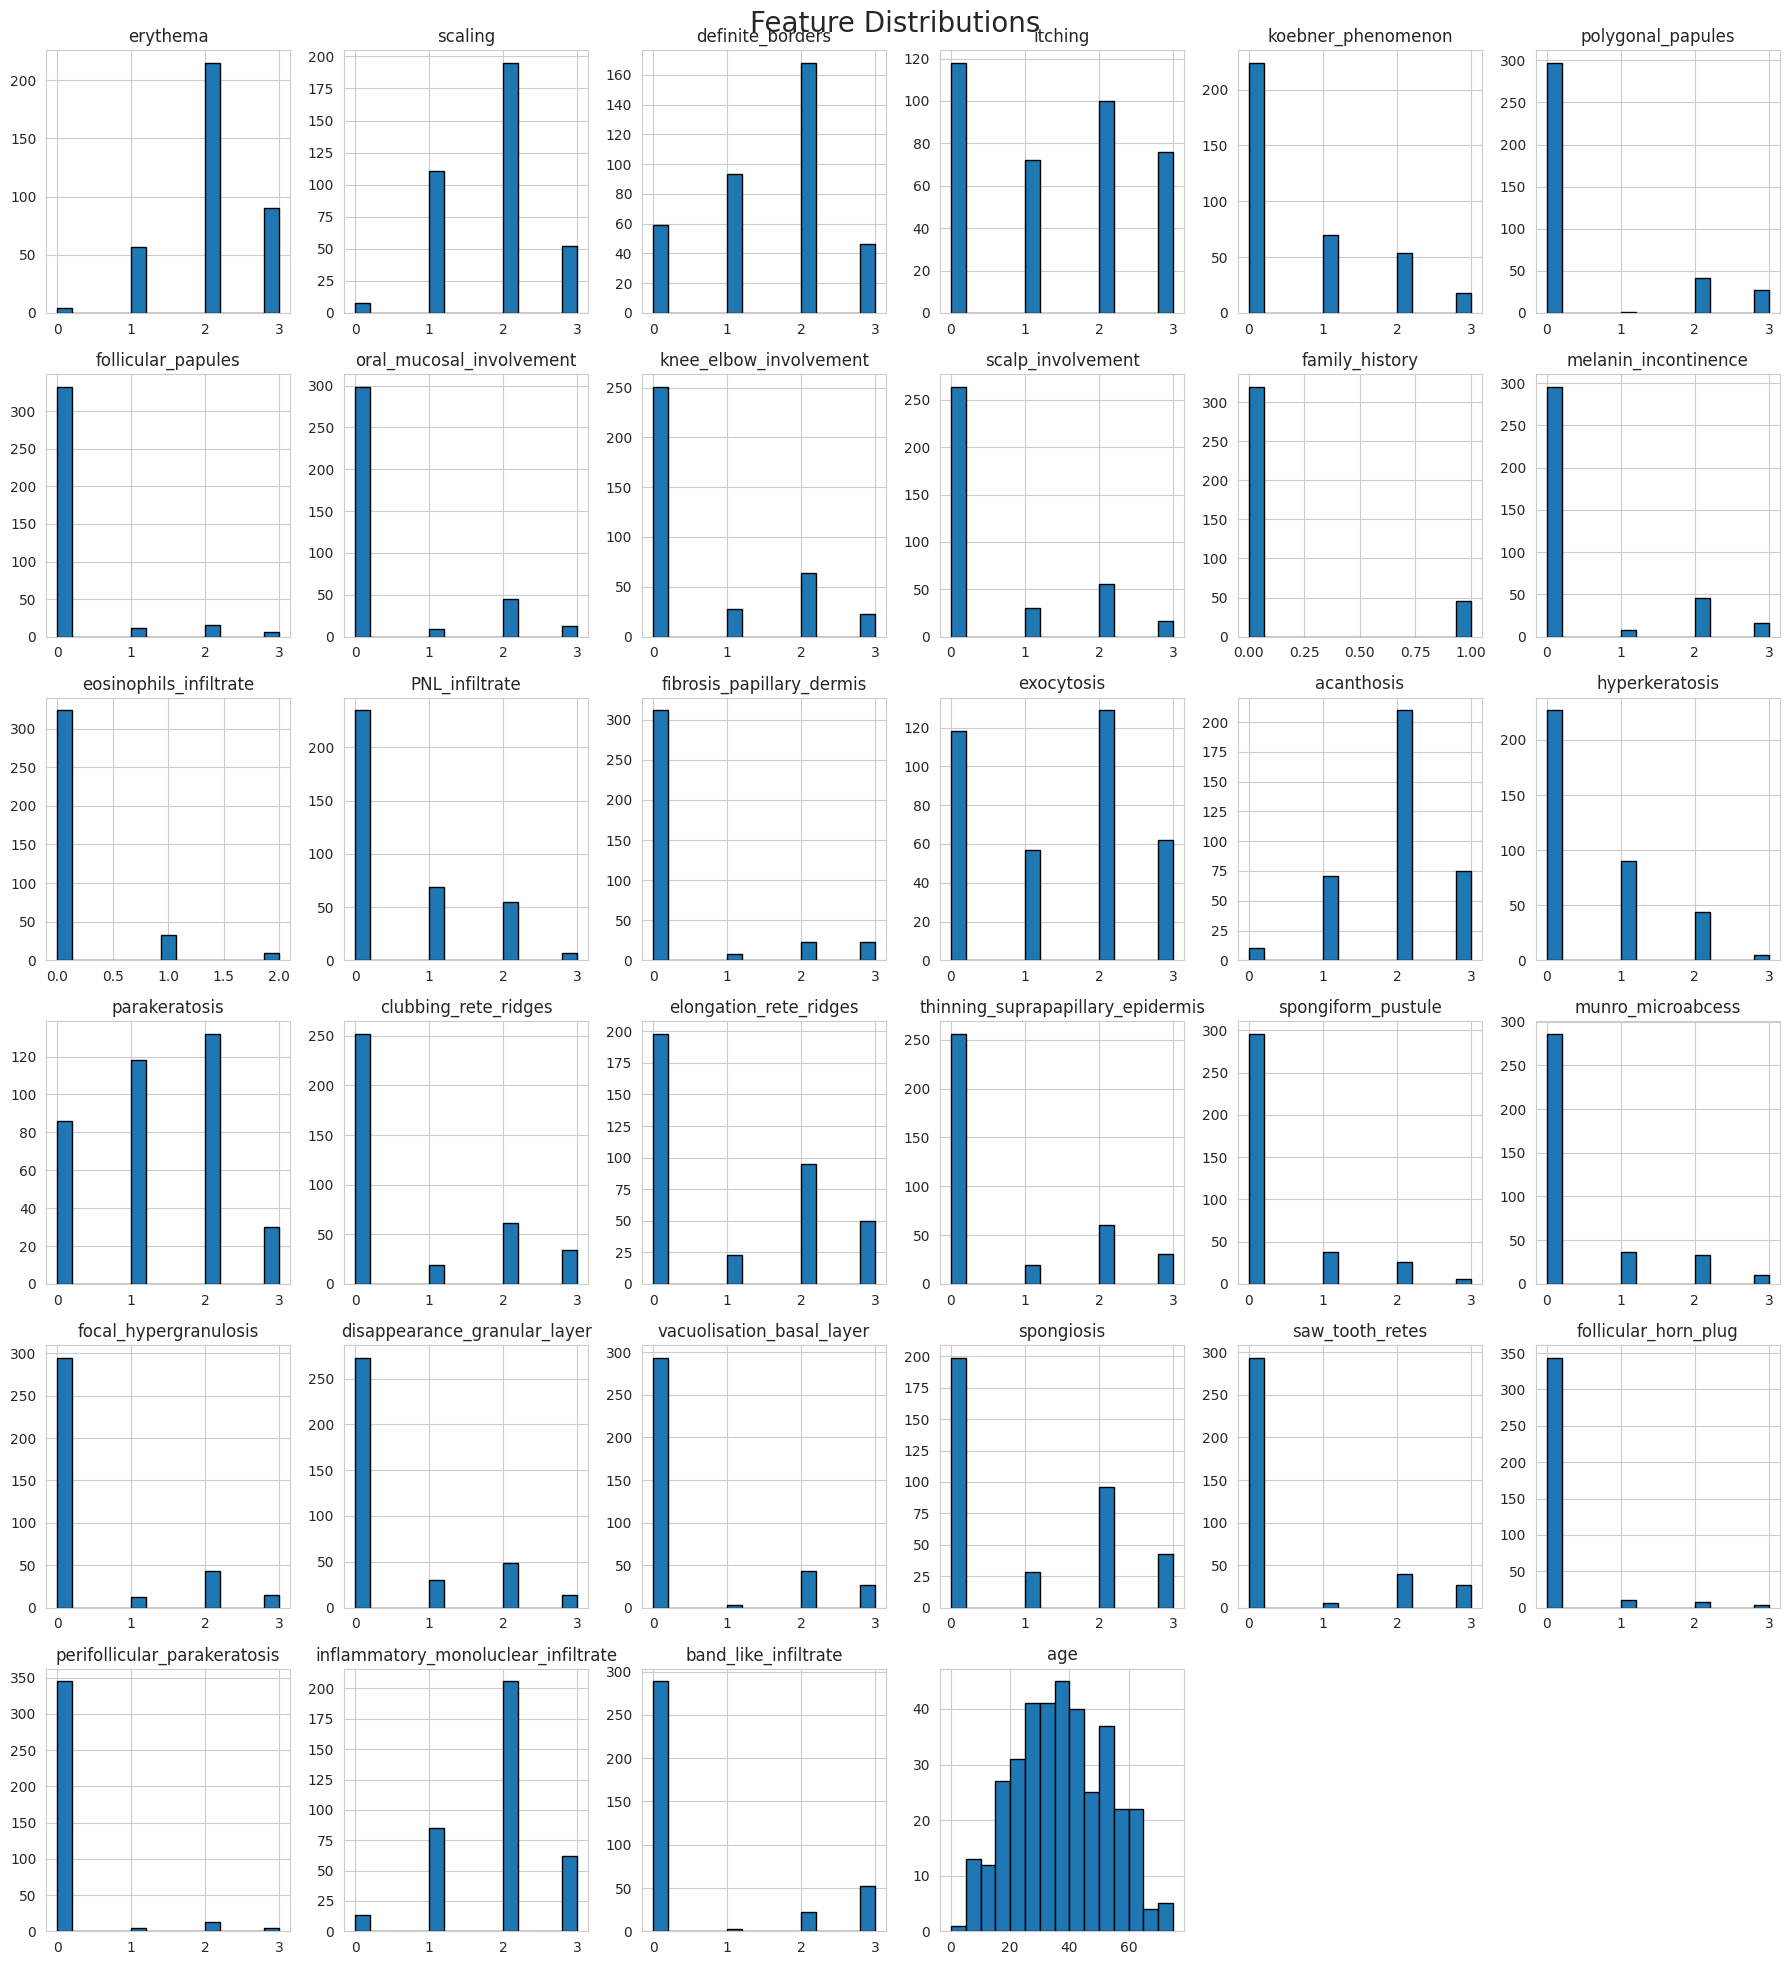

In [9]:
X.hist(figsize=(18, 20), bins=15, edgecolor="black")
plt.suptitle("Feature Distributions", fontsize=20)
plt.tight_layout()
plt.show()

### Box Plots

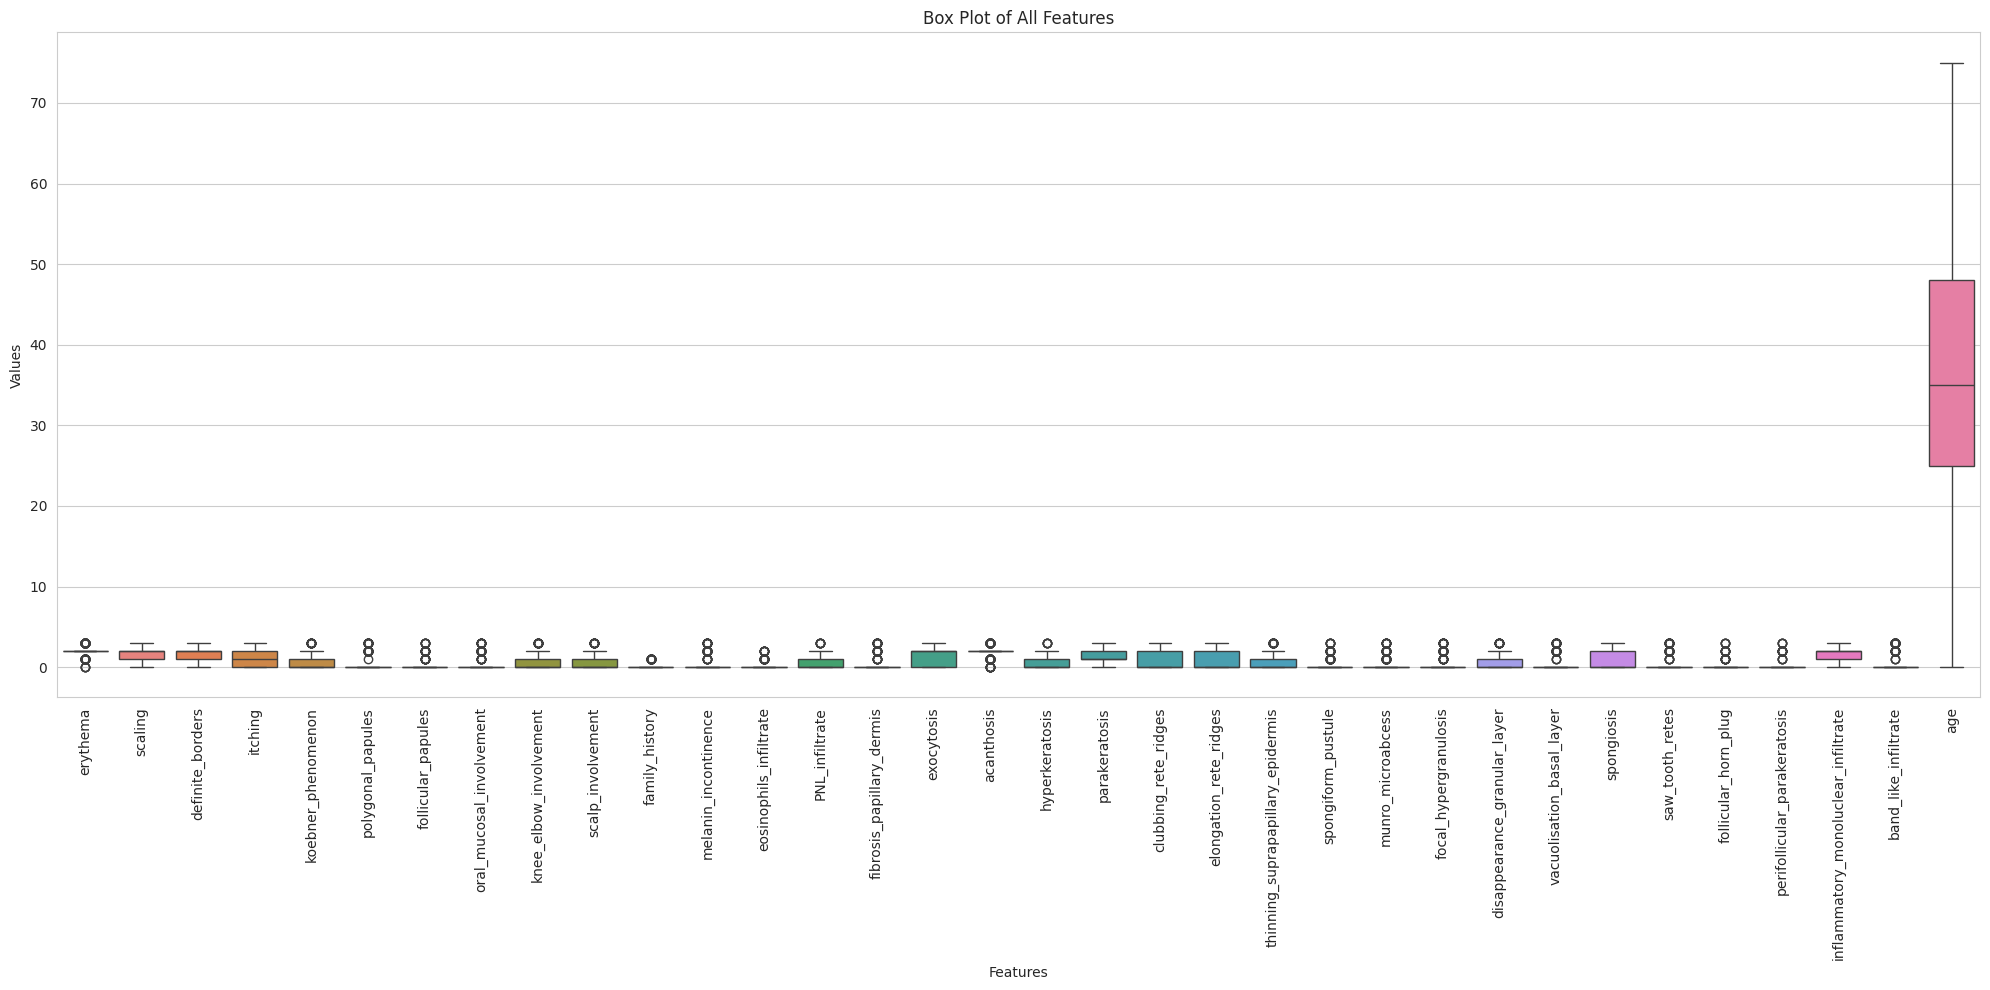

In [10]:
plt.figure(figsize=(20, 10))
sns.boxplot(data=X)
plt.xticks(rotation=90)
plt.title("Box Plot of All Features")
plt.xlabel("Features")
plt.ylabel("Values")
plt.tight_layout()
plt.show()

### Class Distribution

,Class,Disease,Count,Percentage
0,1,Psoriasis,112,30.601093
1,2,Seboreic Dermatitis,61,16.666667
2,3,Lichen Planus,72,19.672131
3,4,Pityriasis Rosea,49,13.387978
4,5,Cronic Dermatitis,52,14.207650
5,6,Pityriasis Rubra Pilaris,20,5.464481


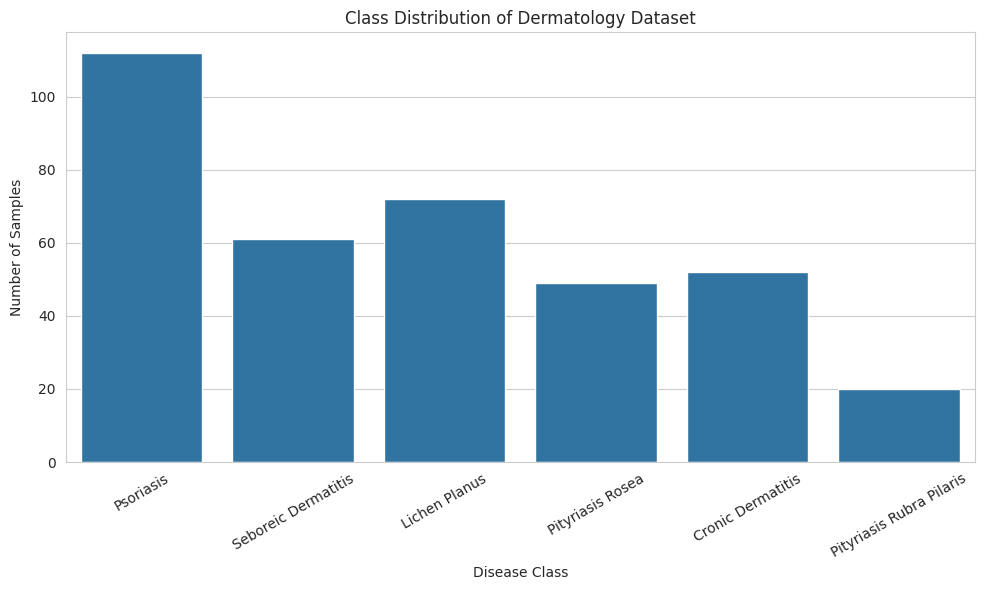

In [11]:
class_names = {
    1: "Psoriasis",
    2: "Seboreic Dermatitis",
    3: "Lichen Planus",
    4: "Pityriasis Rosea",
    5: "Cronic Dermatitis",
    6: "Pityriasis Rubra Pilaris"
}

class_counts = y["Class"].value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Class": class_counts.index,
    "Disease": [class_names[i] for i in class_counts.index],
    "Count": class_counts.values,
    "Percentage": (class_counts.values / len(y) * 100)
})

display(class_distribution)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=[class_names[i] for i in class_counts.index],
    y=class_counts.values
)
plt.title("Class Distribution of Dermatology Dataset")
plt.xlabel("Disease Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Class Distribution Discussion

The six classes are not perfectly balanced. Psoriasis has the largest number of observations, while Pityriasis Rubra Pilaris has the smallest. This imbalance can make a model perform better on majority classes than minority classes. Therefore, stratified splitting and per-class precision, recall and F1-score are important for evaluation.

### Correlation Heatmap

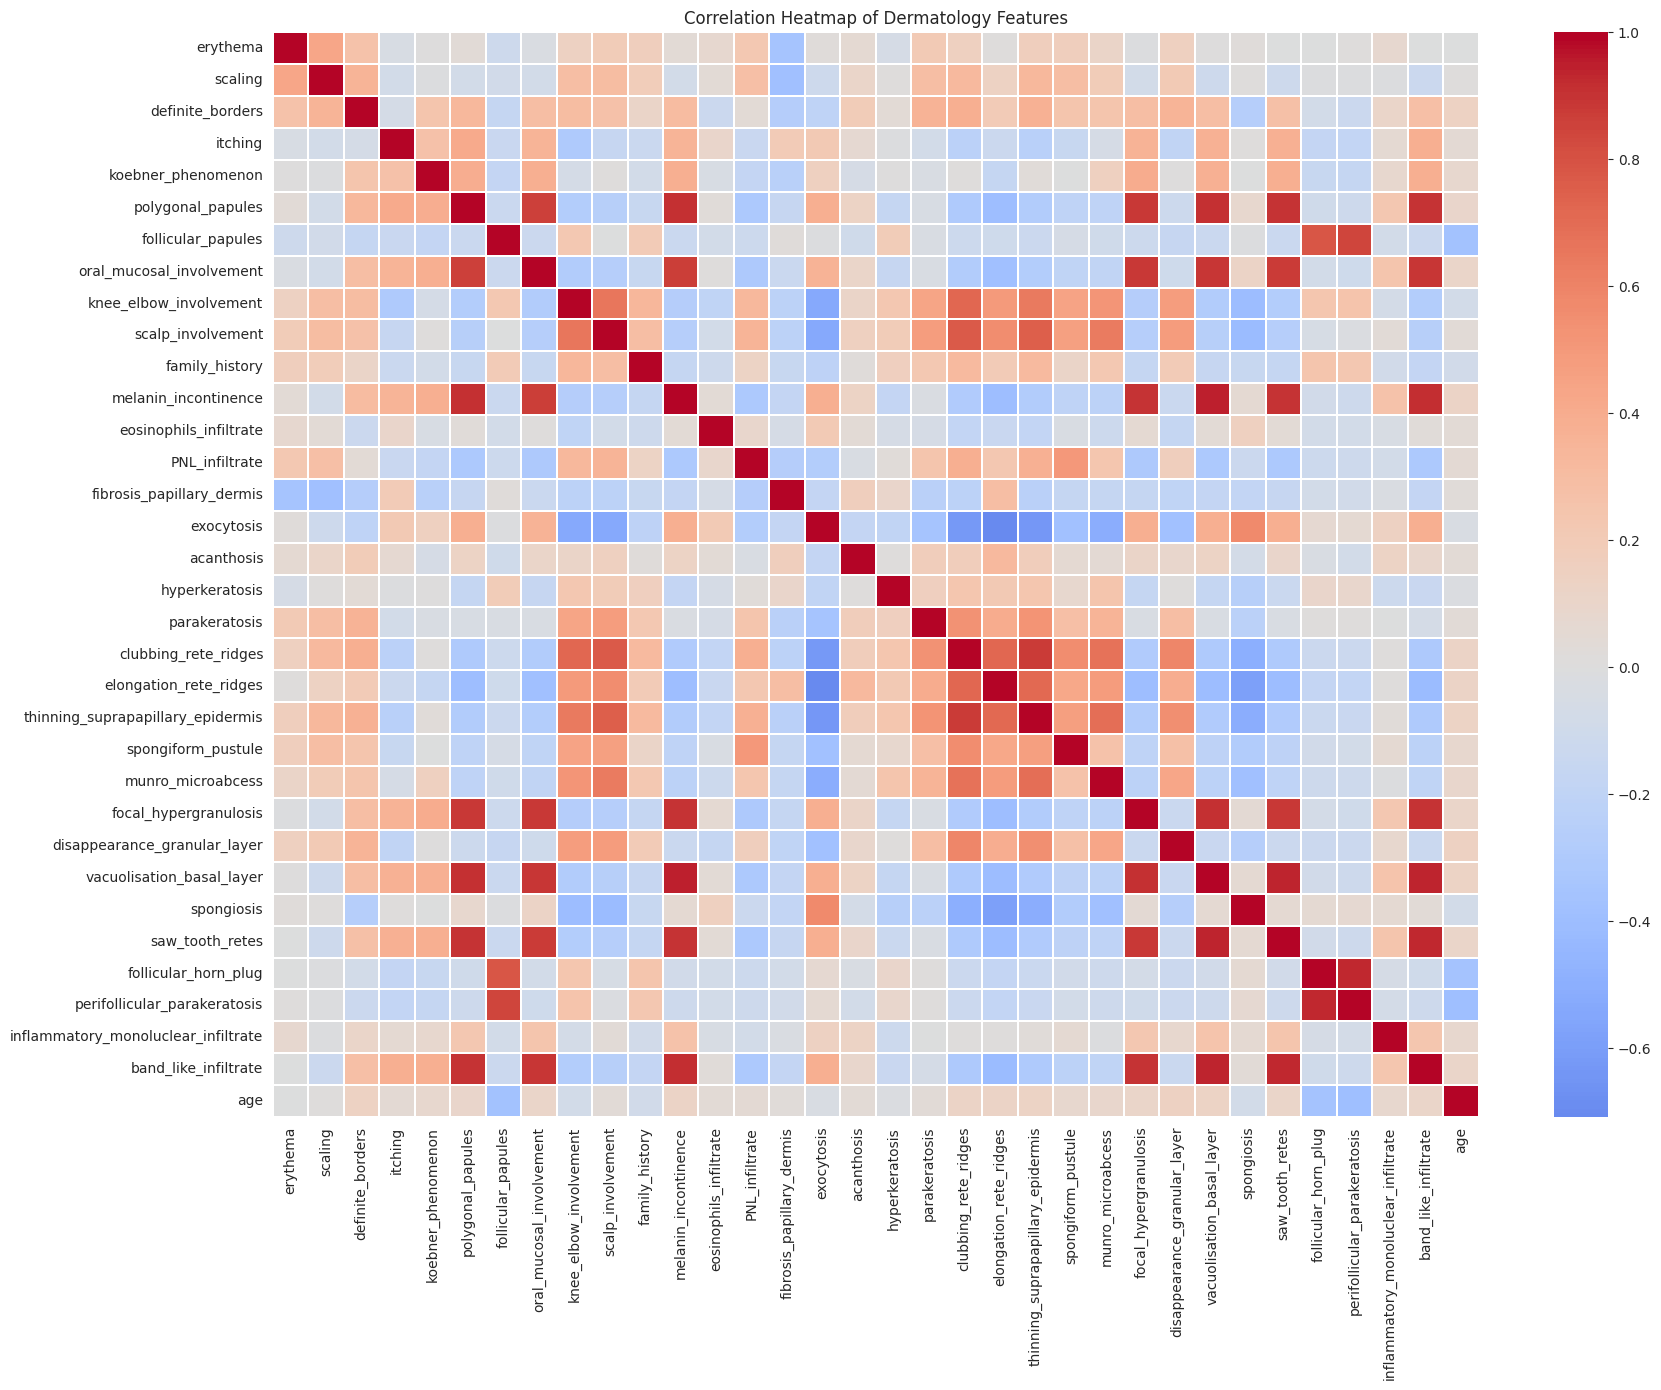

In [12]:
plt.figure(figsize=(18, 14))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation Heatmap of Dermatology Features")
plt.tight_layout()
plt.show()

## Task 2 – Data Preprocessing

In [13]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y["Class"])

print("Original classes:", sorted(y["Class"].unique()))
print("Encoded classes:", sorted(np.unique(y_encoded)))

Original classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Encoded classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 292
Testing samples: 74


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features standardized successfully.")

Features standardized successfully.


## Task 3 – Model Training and Basic Evaluation
Five multiclass algorithms are used: Logistic Regression, KNN, Random Forest, SVM, and Gaussian Naive Bayes.

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Naive Bayes": GaussianNB()
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
KNN trained successfully.
Random Forest trained successfully.
SVM trained successfully.
Naive Bayes trained successfully.


In [17]:
predictions = {}

for name, model in trained_models.items():
    predictions[name] = model.predict(X_test_scaled)

print("Predictions generated for all models.")

Predictions generated for all models.


### Accuracy, Precision, Recall and F1-Score

In [18]:
results = []

for name, model in trained_models.items():
    y_pred = predictions[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.959459,0.968815,0.959459,0.960642
1,KNN,0.905405,0.919305,0.905405,0.908094
2,Random Forest,0.959459,0.960688,0.959459,0.959543
3,SVM,0.972973,0.977477,0.972973,0.972973
4,Naive Bayes,0.864865,0.912646,0.864865,0.845039


### Per-Class Precision, Recall and F1-Score

In [19]:
target_names = [class_names[i] for i in sorted(class_names.keys())]

for name in trained_models:
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=target_names,
            zero_division=0
        )
    )


Logistic Regression
                          precision    recall  f1-score   support

               Psoriasis       1.00      1.00      1.00        23
     Seboreic Dermatitis       1.00      0.83      0.91        12
           Lichen Planus       1.00      0.93      0.97        15
        Pityriasis Rosea       0.77      1.00      0.87        10
       Cronic Dermatitis       1.00      1.00      1.00        10
Pityriasis Rubra Pilaris       1.00      1.00      1.00         4

                accuracy                           0.96        74
               macro avg       0.96      0.96      0.96        74
            weighted avg       0.97      0.96      0.96        74


KNN
                          precision    recall  f1-score   support

               Psoriasis       1.00      0.96      0.98        23
     Seboreic Dermatitis       0.80      0.67      0.73        12
           Lichen Planus       1.00      0.93      0.97        15
        Pityriasis Rosea       0.64      0.90 

### Confusion Matrices

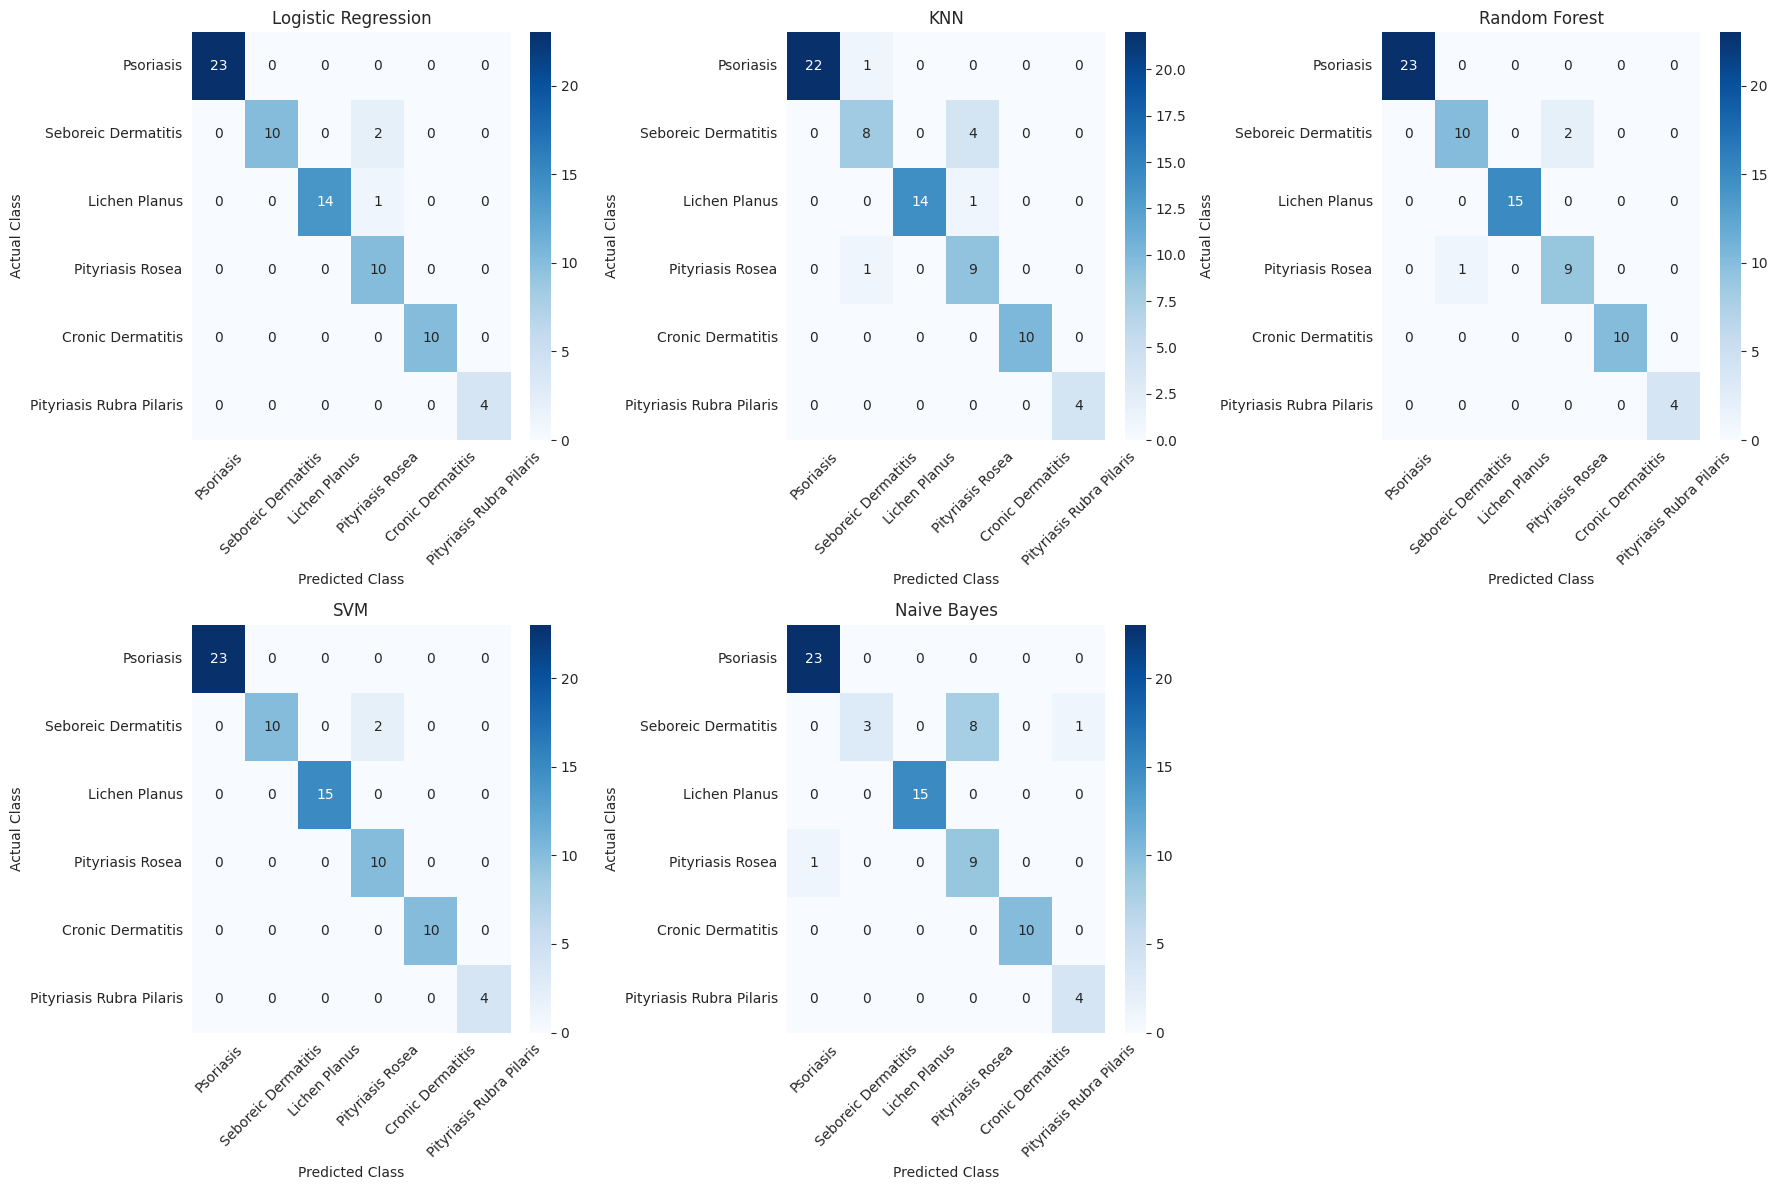

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=target_names,
        yticklabels=target_names
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

# Hide unused subplot
if len(predictions) < len(axes):
    for i in range(len(predictions), len(axes)):
        axes[i].axis("off")

plt.tight_layout()
plt.show()

### Multiclass ROC Curves and AUC
ROC-AUC is calculated using a one-vs-rest strategy.

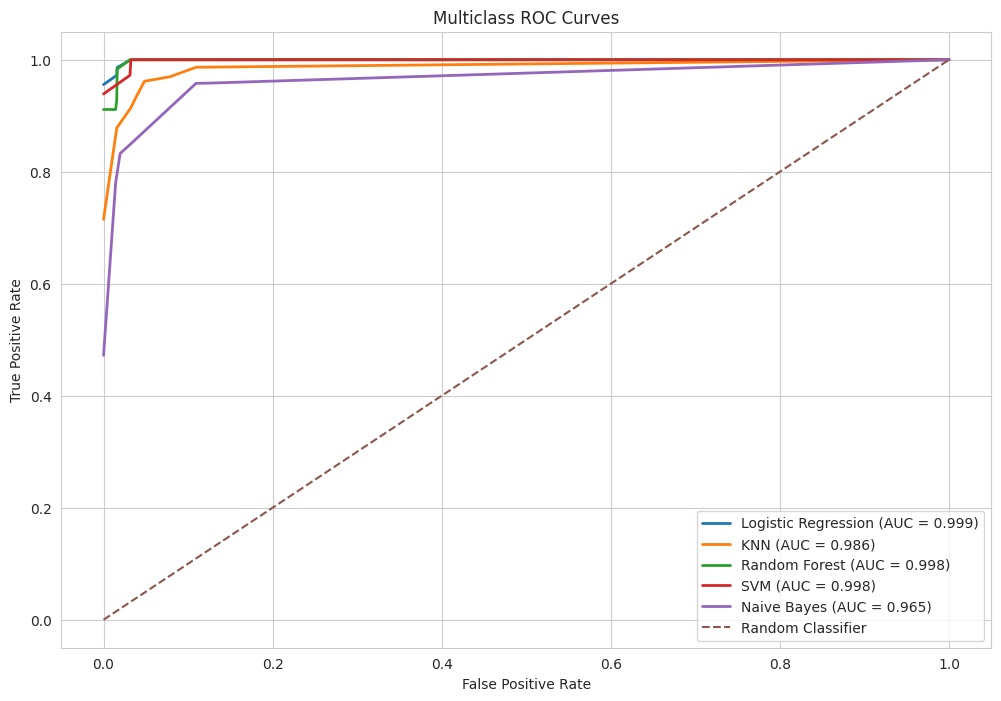

,Model,ROC-AUC
0,Logistic Regression,0.999068
1,KNN,0.986262
2,Random Forest,0.998323
3,SVM,0.998062
4,Naive Bayes,0.965260


In [21]:
n_classes = len(np.unique(y_test))
y_test_binary = label_binarize(y_test, classes=np.arange(n_classes))

auc_results = []

plt.figure(figsize=(12, 8))

for name, model in trained_models.items():
    y_score = model.predict_proba(X_test_scaled)

    auc_score = roc_auc_score(
        y_test_binary,
        y_score,
        multi_class="ovr",
        average="macro"
    )

    auc_results.append({
        "Model": name,
        "ROC-AUC": auc_score
    })

    fpr = {}
    tpr = {}

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(
            y_test_binary[:, i],
            y_score[:, i]
        )

    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)

    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

    mean_tpr /= n_classes

    plt.plot(
        all_fpr,
        mean_tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves")
plt.legend()
plt.grid(True)
plt.show()

auc_df = pd.DataFrame(auc_results)
display(auc_df)

### Final Model Comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.959459,0.968815,0.959459,0.960642,0.999068
1,KNN,0.905405,0.919305,0.905405,0.908094,0.986262
2,Random Forest,0.959459,0.960688,0.959459,0.959543,0.998323
3,SVM,0.972973,0.977477,0.972973,0.972973,0.998062
4,Naive Bayes,0.864865,0.912646,0.864865,0.845039,0.965260


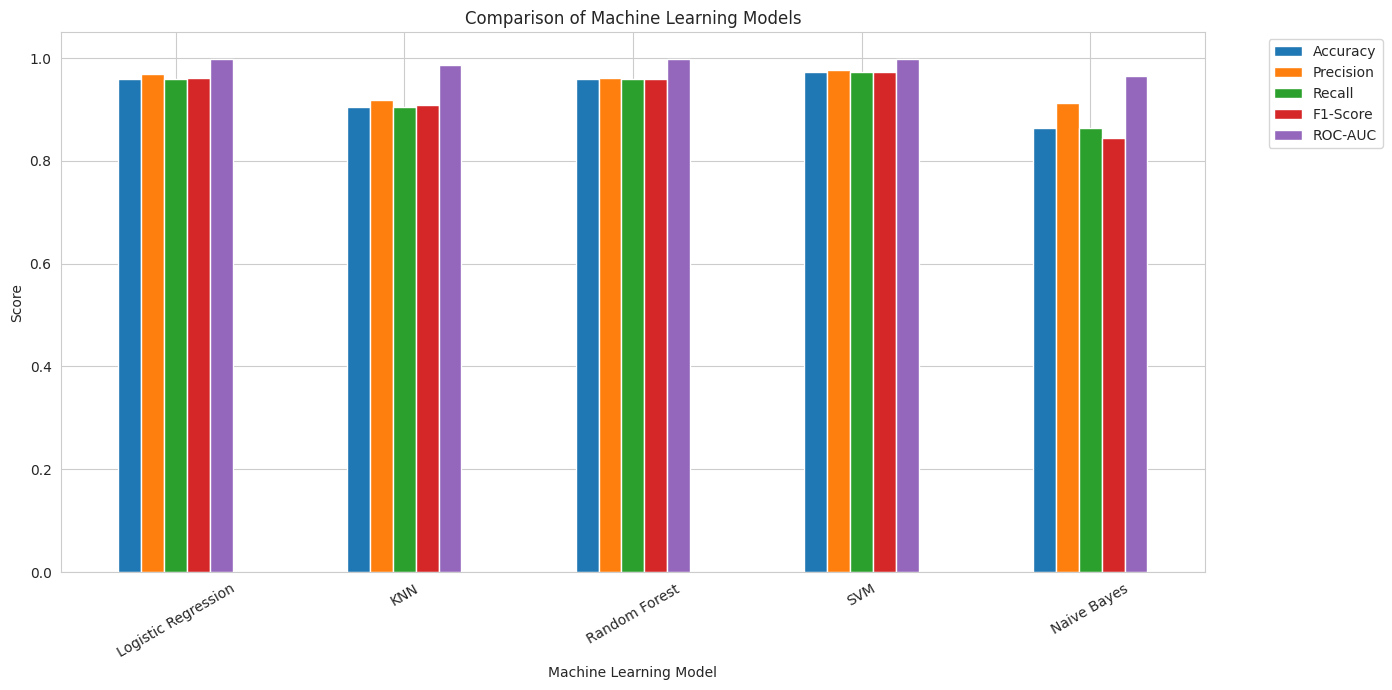

In [22]:
final_results = results_df.merge(auc_df, on="Model")

display(final_results)

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

final_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()